In [16]:
import pandas as pd

# boxplot version
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("../laptop_data_cleaned.csv")

# handle these better with your own dataset, here we are simply dropping these
#df = df.drop(['id', 'date', 'zipcode', 'lat', 'long'], axis=1)

# since price is a continuous variable, it's not practical to use it 
# in some of the visualizations. binning creates a categorical variable
# out of a continuous variable, allowing us the use it in visualizations
# this example bins the price into five categories

# in this dataset, there's some outliers of expensive houses on the high end
# that makes it difficult to compare categories
# this example removes the top 2% houses to make it easier to read the following charts
df = df.query('Price < Price.quantile(q=0.98)')

# for easier visualizations, we'll split the continuous price into categories
df['binned_price'] = pd.cut(df['Price'], bins=5, labels=['Low', 'Below Average', 'Average', 'Above Average', 'High'])

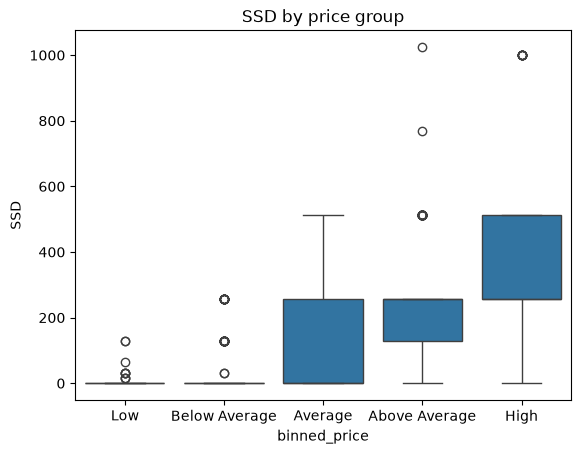

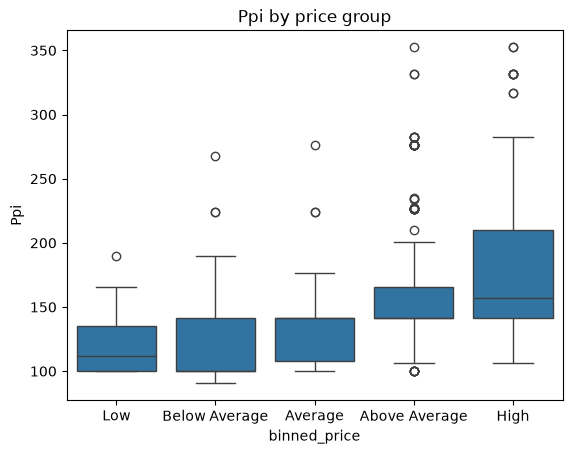

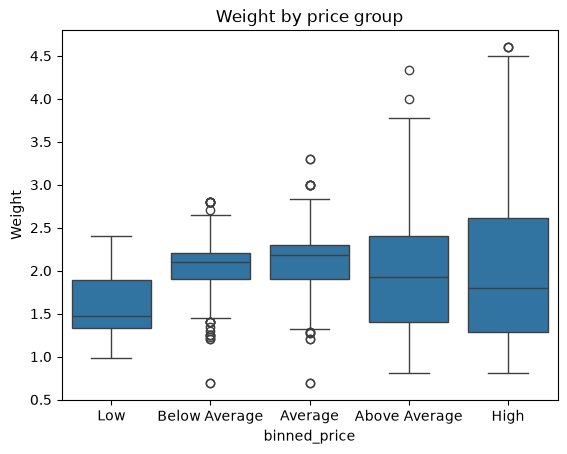

In [17]:
# Boxplots for SSD, Ppi, Weight against binned_price
for col in ["SSD", "Ppi", "Weight"]:
    sns.boxplot(data=df, x="binned_price", y=col)
    plt.title(f"{col} by price group")
    plt.show()

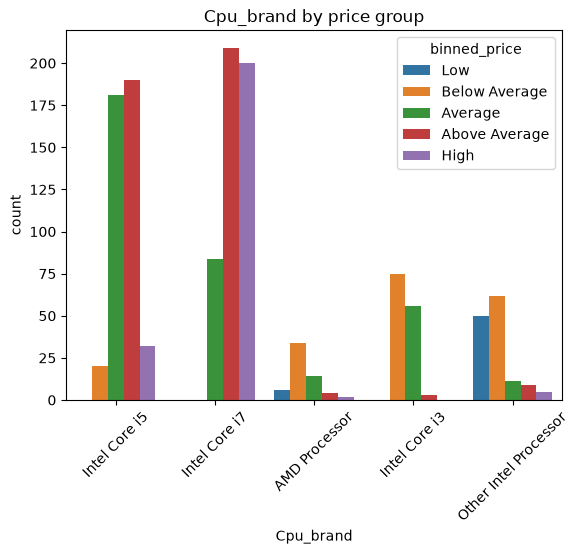

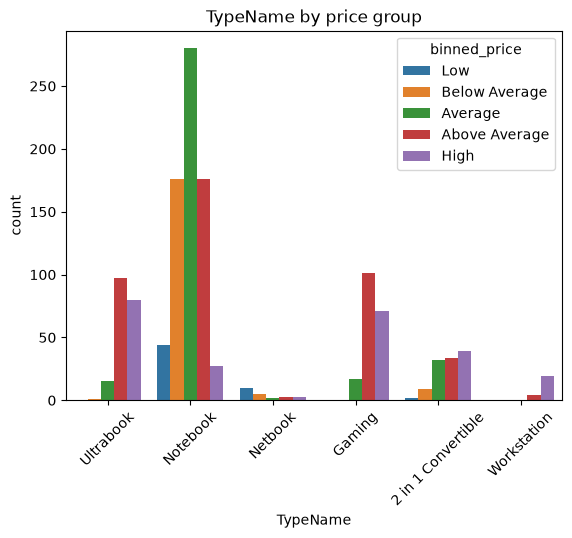

In [18]:
#Count plots for Cpu_brand and TypeName 
for col in ["Cpu_brand", "TypeName"]:
    sns.countplot(data=df, x=col, hue="binned_price")
    plt.xticks(rotation=45)
    plt.title(f"{col} by price group")
    plt.show()

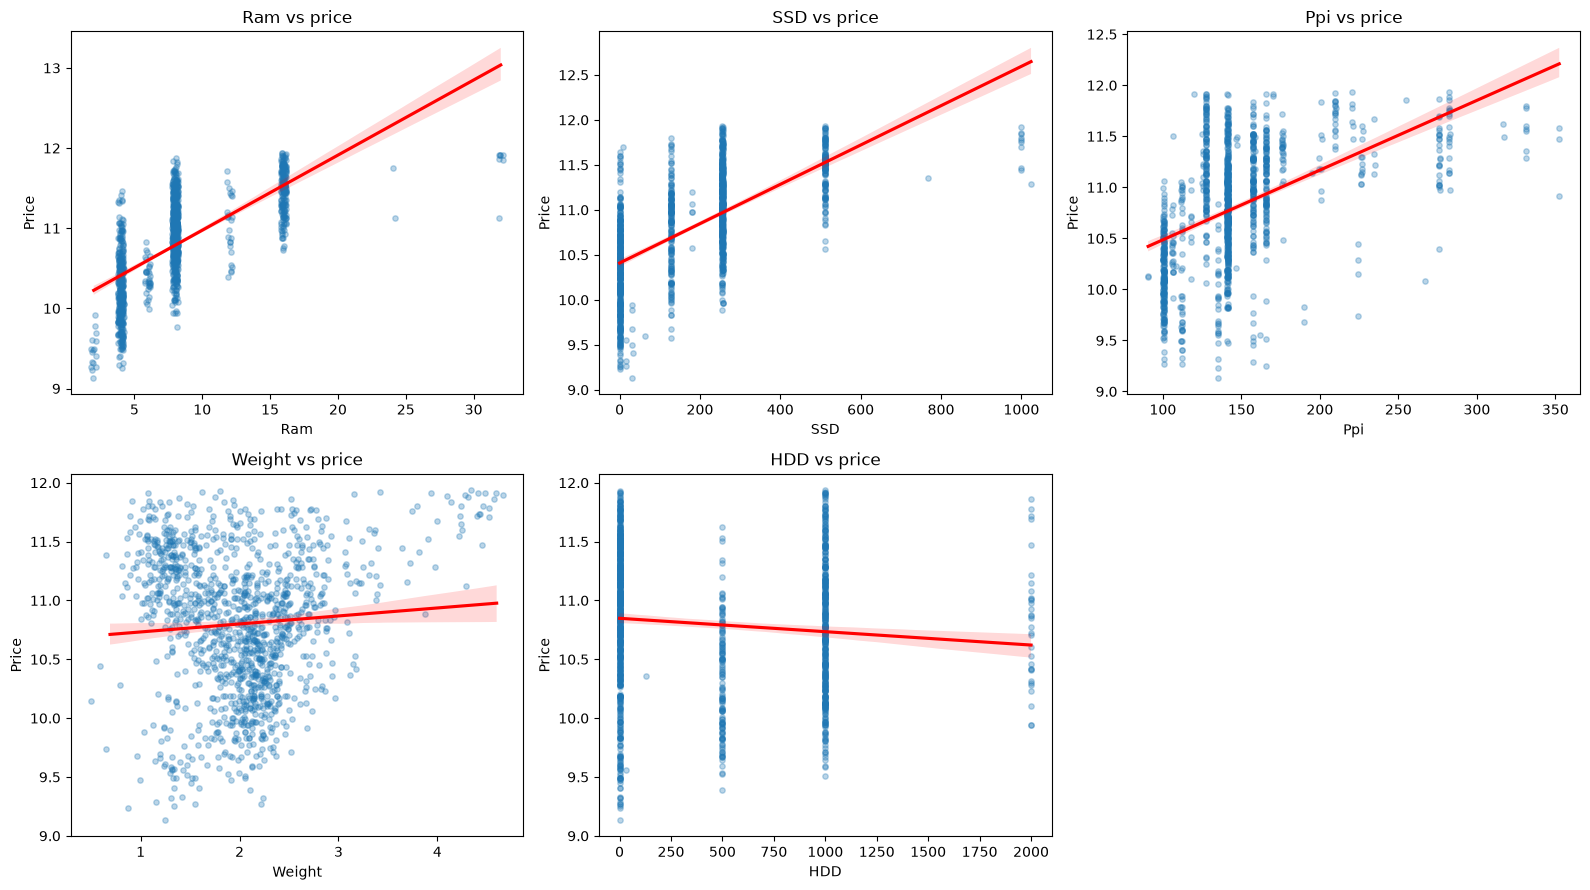

In [19]:
# Numeric features vs Price (scatter and regression plots)
import seaborn as sns
import matplotlib.pyplot as plt

num_cols = ["Ram", "SSD", "Ppi", "Weight", "HDD"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, col in zip(axes, num_cols):
    sns.regplot(data=df, x=col, y="Price", ax=ax,
                x_jitter=0.2, scatter_kws={"alpha": 0.3, "s": 15},
                line_kws={"color": "red"})
    ax.set_title(f"{col} vs price")

axes[-1].axis("off")
plt.tight_layout()
plt.show()